# WEEK 9: HOUSE PRICE PREDICTION



In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [14]:
df = pd.read_csv("house_data.csv")
print(df.shape)
display(df.head())
display(df.info())
display(df.describe(include="all"))
print(df.isna().sum())


(300, 8)


,Property_ID,Area,Bedrooms,Bathrooms,Age,Location,Property_Type,Price
0,PROP0001,3712,4,3,36,Rural,House,22260000
1,PROP0002,1591,4,1,35,Suburb,House,16057500
2,PROP0003,1646,4,3,20,Rural,Villa,12730000
3,PROP0004,4814,1,2,13,City Center,Villa,50840000
4,PROP0005,800,4,2,38,Suburb,Apartment,10650000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Property_ID    300 non-null    object
 1   Area           300 non-null    int64 
 2   Bedrooms       300 non-null    int64 
 3   Bathrooms      300 non-null    int64 
 4   Age            300 non-null    int64 
 5   Location       300 non-null    object
 6   Property_Type  300 non-null    object
 7   Price          300 non-null    int64 
dtypes: int64(5), object(3)
memory usage: 18.9+ KB


None

,Property_ID,Area,Bedrooms,Bathrooms,Age,Location,Property_Type,Price
count,300,300.00000,300.000000,300.000000,300.000000,300,300,3.000000e+02
unique,300,NaN,NaN,NaN,NaN,3,3,NaN
top,PROP0001,NaN,NaN,NaN,NaN,Suburb,House,NaN
freq,1,NaN,NaN,NaN,NaN,105,107,NaN
mean,NaN,2759.70000,3.033333,2.026667,25.000000,NaN,NaN,2.488366e+07
std,NaN,1297.68143,1.467219,0.792495,14.332646,NaN,NaN,1.266525e+07
min,NaN,520.00000,1.000000,1.000000,0.000000,NaN,NaN,3.695000e+06
25%,NaN,1675.75000,2.000000,1.000000,12.000000,NaN,NaN,1.527750e+07
50%,NaN,2738.00000,3.000000,2.000000,25.500000,NaN,NaN,2.236500e+07
75%,NaN,3801.25000,4.000000,3.000000,36.250000,NaN,NaN,3.460812e+07


Property_ID      0
Area             0
Bedrooms         0
Bathrooms        0
Age              0
Location         0
Property_Type    0
Price            0
dtype: int64


In [15]:
target = "Price"
features = ["Area","Bedrooms","Bathrooms","Age","Location","Property_Type"]
X = df[features]
y = df[target]


In [16]:
x = df["Area"].values.astype(float)
y_s = df["Price"].values.astype(float)

x_mean = x.mean()
y_mean = y_s.mean()

slope = ((x-x_mean)*(y_s-y_mean)).sum() / ((x-x_mean)**2).sum()
intercept = y_mean - slope*x_mean

pred_scratch = intercept + slope*x
print("Slope:", slope)
print("Intercept:", intercept)
print("R²:", r2_score(y_s, pred_scratch))


Slope: 7771.692409121677
Intercept: 3436118.7918802425
R²: 0.6340733925305242


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)


In [18]:
numeric_features = ["Area","Bedrooms","Bathrooms","Age"]
categorical_features = ["Location","Property_Type"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])


In [19]:
linear_model = Pipeline([
    ("prep", preprocessor),
    ("model", LinearRegression())
])
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)


In [20]:
poly_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("scale", StandardScaler()),
        ("poly", PolynomialFeatures(degree=2, include_bias=False))
    ]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

poly_model = Pipeline([
    ("prep", poly_preprocessor),
    ("model", LinearRegression())
])
poly_model.fit(X_train, y_train)
poly_pred = poly_model.predict(X_test)


In [21]:
tree_model = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeRegressor(max_depth=6, random_state=42))
])

forest_model = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300, max_depth=10, random_state=42, n_jobs=-1
    ))
])

tree_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)
forest_pred = forest_model.predict(X_test)


In [22]:
def evaluate_model(name, y_true, pred):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, pred),
        "MSE": mean_squared_error(y_true, pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
        "R2": r2_score(y_true, pred)
    }

results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, linear_pred),
    evaluate_model("Polynomial Regression", y_test, poly_pred),
    evaluate_model("Decision Tree", y_test, tree_pred),
    evaluate_model("Random Forest", y_test, forest_pred)
])
display(results.sort_values("R2", ascending=False))


,Model,MAE,MSE,RMSE,R2
3,Random Forest,1.463091e+06,3.917323e+12,1.979223e+06,0.972494
0,Linear Regression,2.188736e+06,8.454331e+12,2.907633e+06,0.940637
2,Decision Tree,2.491788e+06,9.603067e+12,3.098882e+06,0.932571
1,Polynomial Regression,2.367902e+06,1.011615e+13,3.180590e+06,0.928968


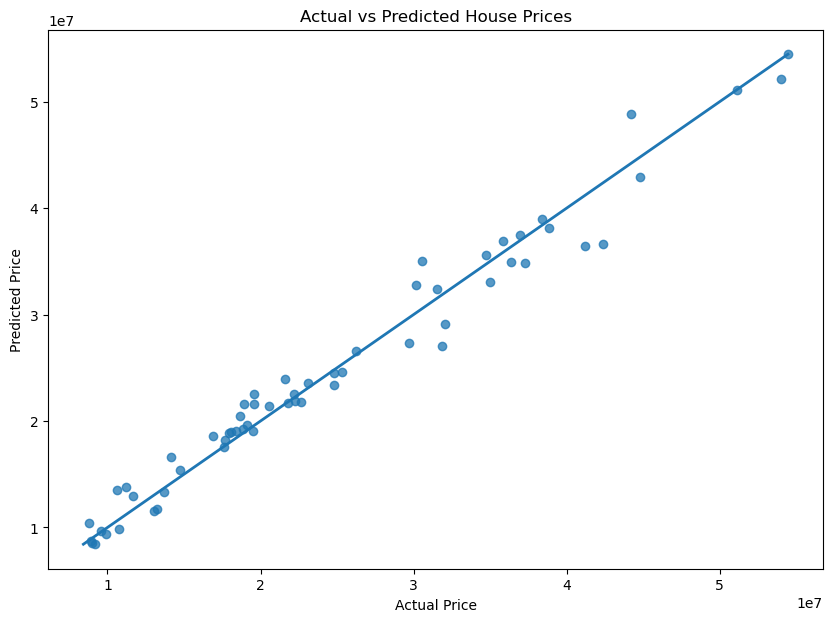

In [23]:
best_pred = forest_pred
plt.figure(figsize=(10,7))
plt.scatter(y_test, best_pred, alpha=0.75)
mn=min(y_test.min(),best_pred.min())
mx=max(y_test.max(),best_pred.max())
plt.plot([mn,mx],[mn,mx],linewidth=2)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.show()


In [24]:
# Random Forest feature importance after preprocessing
forest_pipe = forest_model
feature_names = forest_pipe.named_steps["prep"].get_feature_names_out()
importance = forest_pipe.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))


,Feature,Importance
0,num__Area,0.686742
4,cat__Location_City Center,0.152888
5,cat__Location_Rural,0.099587
6,cat__Location_Suburb,0.029409
1,num__Bedrooms,0.019506
3,num__Age,0.007875
2,num__Bathrooms,0.001783
9,cat__Property_Type_Villa,0.000818
7,cat__Property_Type_Apartment,0.000794
8,cat__Property_Type_House,0.000598
